Dataset: 'spec_dens_40' from group 'spec_dens' | i:0..2879, j:0..38
   Property: title | Juno Waves - Electric Field Spectral Density%{xCacheResInfo}
   Property: sourceId | das2_cache_rdr

   Data Dimension : spec_dens
      Property: label | V!a2!nm!a-2!nHz!a-1!n
      Property: scaleType | log
      Property: range | [1e-18, 0.01] V**2 m**-2 Hz**-1
      Property: summary | Amplitudes from the HFRH Receiver Band

      Variable: spec_dens['center'][i,j] (float64) V**2 m**-2 Hz**-1

   Coordinate Dimension : Time
      Property: tagWidth | 30.0 s
      Property: label | SCET %{RANGE}
      Property: cacheRange | [2017-10-31T20, 2017-11-01T04] UTC
      Property: cacheResInfo |  (Intrinsic Resolution)

      Variable: Time['center'][i,-] (datetime64[ns]) ns1970

   Coordinate Dimension : frequency
      Property: label | Freq. (Hz)
      Property: scaleType | log

      Variable: frequency['center'][-,j] (float64) Hz



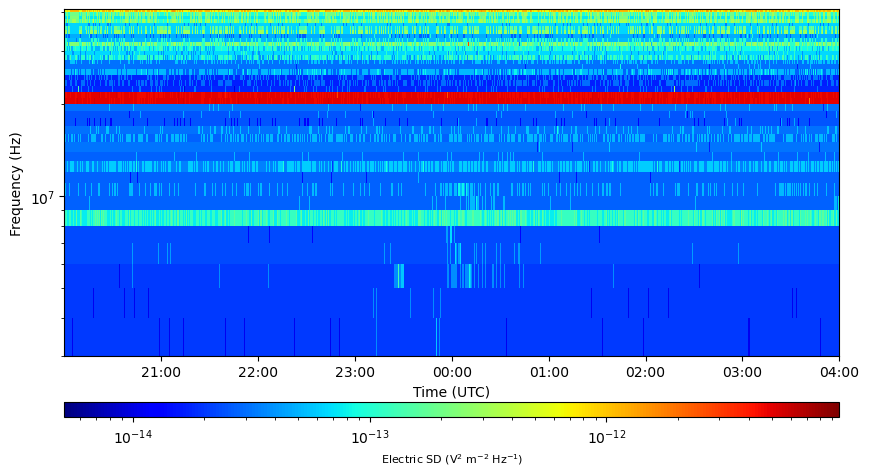

In [32]:
import das2
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import matplotlib.dates as mdates
from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u
from matplotlib.dates import DateFormatter, HourLocator, MinuteLocator
import matplotlib.colors as colors


start_time = '2017-10-31T20:00'
end_time = '2017-11-01T04:00'

src = das2.get_source( 'tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2' )
dataset = src.get( {'time' : (start_time, end_time)} )[0]

print(dataset)

vX = dataset['Time']['center']
vY = dataset['frequency']['center']
vZ = dataset['spec_dens']['center']

time_spec = vX.array
frequency_spec = vY.array
electric_SD_spec = vZ.array

     
# Create a spectrogram plot
fig, das_ax = plt.subplots(figsize=(10, 6))
scaleZ = colors.LogNorm(vmin=electric_SD_spec.min(), vmax=electric_SD_spec.max())
das_ax.pcolormesh(time_spec,frequency_spec,electric_SD_spec, norm=scaleZ, cmap='jet')
cbar = fig.colorbar(das_ax.collections[0], ax=das_ax, orientation='horizontal', aspect=50, pad=0.1)
das_ax.set_yscale('log')
das_ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
das_ax.set_xlabel('Time (UTC)')
das_ax.set_ylabel('Frequency (Hz)')
cbar.set_label(r"Electric SD (V$^2$ m$^{-2}$ Hz$^{-1}$)", fontsize=8)

In [37]:
import das2
import numpy as np

# ─── USER CONFIGURATION ────────────────────────────────────────────────────────
# Modify these to the desired time window for which you want the electron
# cyclotron frequency. Times must be ISO 8601 strings with UTC (the “Z” suffix).
start_time = '2021-01-01T00:00:00.000Z'
end_time   = '2021-01-01T01:00:00.000Z'

# DAS2 source URI for Juno FGM–derived electron cyclotron resonance frequency
source_uri = 'tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2'

# ─── 1) Get a handle to the DAS2 source ───────────────────────────────────────
src = das2.get_source(source_uri)

# ─── 2) Fetch the dataset over the specified time interval ───────────────────
# The .get() call returns a list of xarray‐like datasets. Usually there is one
# entry per “stream” on that source. We take the first entry here.
datasets = src.get({'time': (start_time, end_time, 1)})
if len(datasets) == 0:
    raise RuntimeError(f'No data returned between {start_time} and {end_time}.')

ds = datasets[0]
print(datasets)
# ─── 3) Inspect available variables ──────────────────────────────────────────
# It is helpful to print out the keys so you know which variable name corresponds
# to the electron cyclotron frequency. Typically, the DAS2 server will name it
# something like 'Electron_Cyclotron_Frequency' or 'f_ce'. Adjust the extraction
# below once you confirm the exact key.
print("Available dataset keys:", list(ds.keys()))

# ─── 4) Extract the time axis ─────────────────────────────────────────────────
# Most DAS2 data streams have a ‘Time’ coordinate with a subkey ‘center’.
# This returns a numpy array of datetime64 objects (or floats, depending on build).
time_arr = ds['time']['center'].array
print(f'Fetched {time_arr.size} time samples.')

# ─── 5) Extract the electron cyclotron frequency array ───────────────────────
# Replace 'f_ce' with whatever key you saw in ds.keys() that corresponds to
# the electron cyclotron resonance. For example, it might be 'Electron_Cyclotron_Frequency',
# or simply 'electroncyclotron'. Check the printed keys above.
freq_key = 'fce'  # ← Change this if your dataset uses a different variable name.
if freq_key not in ds:
    raise KeyError(f"Variable '{freq_key}' not found in dataset; available keys are: {list(ds.keys())}")

# The ‘center’ subkey typically holds the pointwise values. Some DAS2 streams also
# have ‘min’/’max’ or ’left’/’right’. We assume ‘center’ is what you want.
freq_arr = ds[freq_key]['center'].array
print(f'Fetched {freq_arr.size} frequency samples (Hz).')

# ─── 6) (Optional) Verify shapes and alignments ───────────────────────────────
# Often, for a 1D time series like electron cyclotron frequency, time_arr and
# freq_arr have the same length. But if for any reason freq_arr is multi‐dimensional,
# inspect its shape below:
print('time_arr shape:', np.shape(time_arr))
print(f'{freq_key} array shape:', np.shape(freq_arr))

# ─── 7) (Optional) Example: print first few values ────────────────────────────
print('\nFirst five timestamps and corresponding f_ce values:')
for t, f in zip(time_arr[:5], freq_arr[:5]):
    print(f'  {t} → {f:.3f} Hz')

# At this point, `time_arr` is a 1D array of timestamps and `freq_arr` is the
# corresponding 1D array of electron cyclotron frequencies in Hz. You can now
# proceed to plot these, interpolate them, or save them to disk, etc.


Available dataset keys: ['coord:time', 'data:fce']
Fetched 3606 time samples.
Fetched 3606 frequency samples (Hz).
time_arr shape: (3606,)
fce array shape: (3606,)

First five timestamps and corresponding f_ce values:
  2021-01-01T00:00:00.500000000 → 2475.158 Hz
  2021-01-01T00:00:01.500000000 → 2474.704 Hz
  2021-01-01T00:00:02.500000000 → 2474.137 Hz
  2021-01-01T00:00:00.500000000 → 2475.158 Hz
  2021-01-01T00:00:01.500000000 → 2474.704 Hz
